Returns	- How much does META's price change every 5 minutes?<br>
Volatility - How unpredictable are its price movements?<br>
Volume - When does trading activity increase or decrease?<br>
Correlation	- Which market variables move together?<br>
Time-of-day patterns -	Does META behave differently at different times?<br>

### Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

In [2]:
plt.style.use("ggplot")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.6f}".format)

### Loading the dataset

In [4]:
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (PROJECT_ROOT / "data" / "raw" / "META_5min.csv")

df = pd.read_csv(DATA_PATH)

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

# Convert timestamps to New York time
df["ny_timestamp"] = (
    df["timestamp"]
    .dt.tz_convert("America/New_York")
)

# Extract trading date and time
df["trading_date"] = df["ny_timestamp"].dt.date

df["time"] = df["ny_timestamp"].dt.time

df.head()

,symbol,timestamp,open,high,low,close,volume,trade_count,vwap,ny_timestamp,trading_date,time
0,META,2025-11-03 14:30:00+00:00,656.000000,657.650000,652.000000,653.710000,1542478.000000,63943.000000,655.216851,2025-11-03 09:30:00-05:00,2025-11-03,09:30:00
1,META,2025-11-03 14:35:00+00:00,653.710000,656.960000,653.500100,653.900000,715405.000000,28532.000000,654.975565,2025-11-03 09:35:00-05:00,2025-11-03,09:35:00
2,META,2025-11-03 14:40:00+00:00,653.845000,655.140000,652.010000,653.680000,619718.000000,22155.000000,653.820137,2025-11-03 09:40:00-05:00,2025-11-03,09:40:00
3,META,2025-11-03 14:45:00+00:00,653.680000,655.219900,652.260000,654.985000,578428.000000,20312.000000,654.103077,2025-11-03 09:45:00-05:00,2025-11-03,09:45:00
4,META,2025-11-03 14:50:00+00:00,654.940000,657.060000,653.721500,655.740000,592915.000000,19193.000000,655.716763,2025-11-03 09:50:00-05:00,2025-11-03,09:50:00


In [5]:
print("Dataset shape:", df.shape)

print("\nDate range:")
print(df["ny_timestamp"].min())
print(df["ny_timestamp"].max())

print("\nTrading days:", df["trading_date"].nunique())

print("\nDataset information:")
df.info()

Dataset shape: (19428, 12)

Date range:
2025-11-03 09:30:00-05:00
2026-10-30 15:55:00-04:00

Trading days: 250

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 19428 entries, 0 to 19427
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype                           
---  ------        --------------  -----                           
 0   symbol        19428 non-null  str                             
 1   timestamp     19428 non-null  datetime64[us, UTC]             
 2   open          19428 non-null  float64                         
 3   high          19428 non-null  float64                         
 4   low           19428 non-null  float64                         
 5   close         19428 non-null  float64                         
 6   volume        19428 non-null  float64                         
 7   trade_count   19428 non-null  float64                         
 8   vwap          19428 non-null  float64                         
 9   ny_timestamp  19

## Return Analysis
Returns tell us how much the pirce moved relative to its previous value.

In [6]:
df["returns"] = (
    df.groupby("trading_date")["close"]
      .pct_change(fill_method=None)*100
)

df[[
    "timestamp",
    "close",
    "returns"
]].head(15)

,timestamp,close,returns
0,2025-11-03 14:30:00+00:00,653.710000,NaN
1,2025-11-03 14:35:00+00:00,653.900000,0.029065
2,2025-11-03 14:40:00+00:00,653.680000,-0.033644
3,2025-11-03 14:45:00+00:00,654.985000,0.199639
4,2025-11-03 14:50:00+00:00,655.740000,0.115270
5,2025-11-03 14:55:00+00:00,656.190000,0.068625
6,2025-11-03 15:00:00+00:00,655.870000,-0.048766
7,2025-11-03 15:05:00+00:00,657.805000,0.295028
8,2025-11-03 15:10:00+00:00,656.970000,-0.126937
9,2025-11-03 15:15:00+00:00,654.838500,-0.324444


In [7]:
returns = df["returns"].dropna()

print("Return Statistics")
print("-----------------")

print("Mean:", returns.mean())
print("Median:", returns.median())
print("Standard Deviation:", returns.std())
print("Minimum:", returns.min())
print("Maximum:", returns.max())
print("Skewness:", returns.skew())
print("Kurtosis:", returns.kurtosis())

Return Statistics
-----------------
Mean: 0.0007698279325925188
Median: -0.0013734304996793067
Standard Deviation: 0.18875014235734672
Minimum: -2.755161633858938
Maximum: 1.724954232687348
Skewness: -0.051118506832556615
Kurtosis: 9.981677264985938


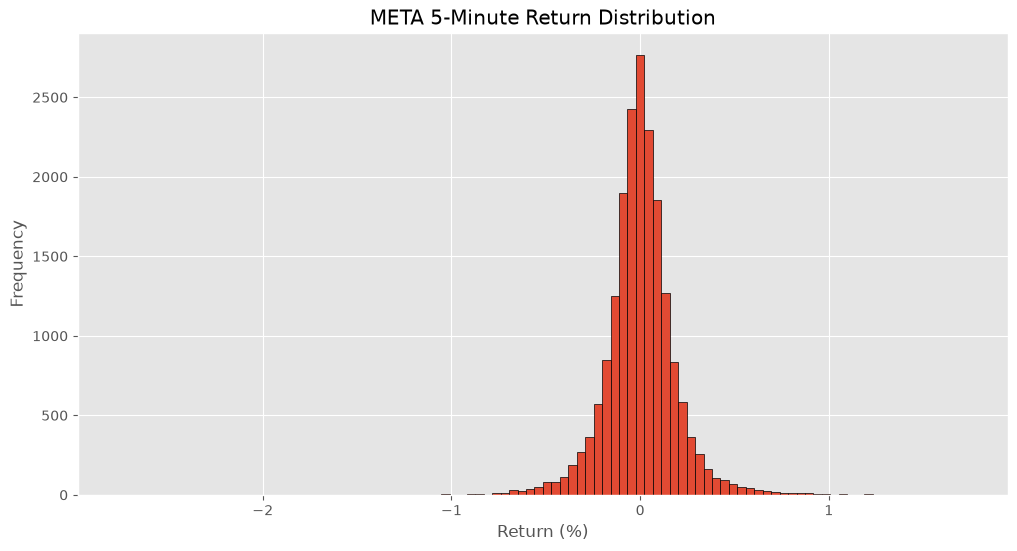

In [8]:
plt.figure(figsize=(12, 6))

plt.hist(
    returns,
    bins=100,
    edgecolor="black"
)

plt.title("META 5-Minute Return Distribution")
plt.xlabel("Return (%)")
plt.ylabel("Frequency")

plt.show()

## Observations: 5-Minute Returns

1. Mean and median returns are close to zero.
   This suggests that short-term price movements are
   generally small.

2. Standard deviation is approximately 0.189%,
   indicating considerable short-term variation.

3. Skewness is close to zero, suggesting an
   approximately symmetric return distribution.

4. Excess kurtosis is approximately 9.98,
   indicating heavy tails and the presence of
   extreme market movements.

5. The observed minimum return is substantially
   larger in magnitude than the maximum return.

Conclusion:
META's 5-minute returns exhibit substantial
short-term variability and heavy-tailed behaviour.
A normal distribution may not adequately describe
the distribution of returns.

## Volatility Analysis

In [9]:
df["rolling_volatility"] = (
    df.groupby("trading_date")["returns"]
      .transform(
          lambda x: x.rolling(
              window=12,
              min_periods=12
          ).std()
      )
)

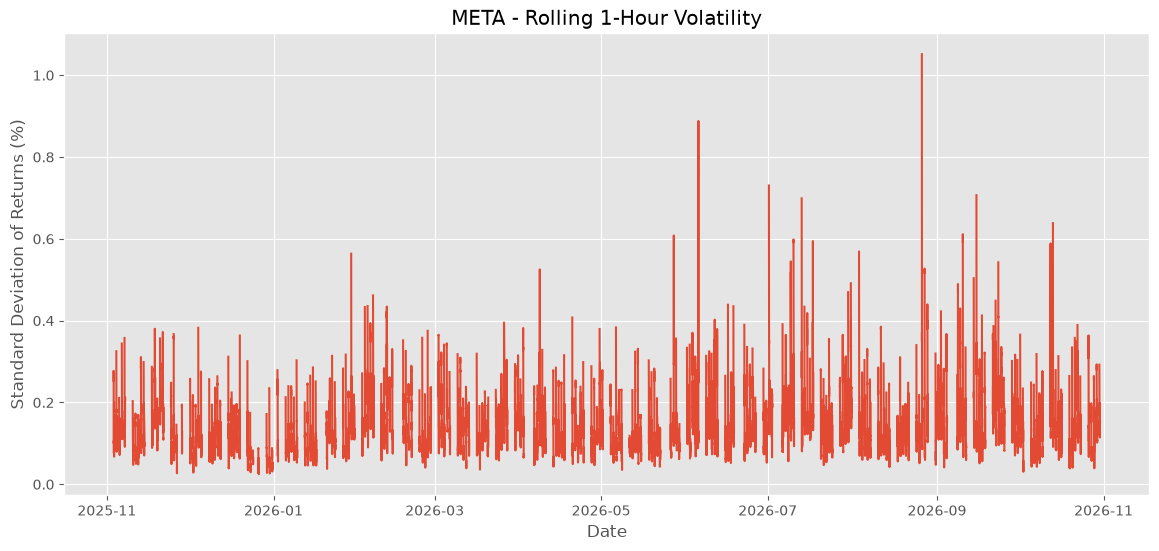

In [10]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["ny_timestamp"],
    df["rolling_volatility"]
)

plt.title("META - Rolling 1-Hour Volatility")
plt.xlabel("Date")
plt.ylabel("Standard Deviation of Returns (%)")

plt.show()

In [11]:
volatility = df["rolling_volatility"].dropna()

print("Volatility Statistics")
print("---------------------")

print("Mean:", volatility.mean())
print("Median:", volatility.median())
print("Standard Deviation:", volatility.std())
print("Minimum:", volatility.min())
print("Maximum:", volatility.max())

Volatility Statistics
---------------------
Mean: 0.14997318869905227
Median: 0.13045607099766177
Standard Deviation: 0.08000009215846562
Minimum: 0.02479251085541076
Maximum: 1.0514192508507316


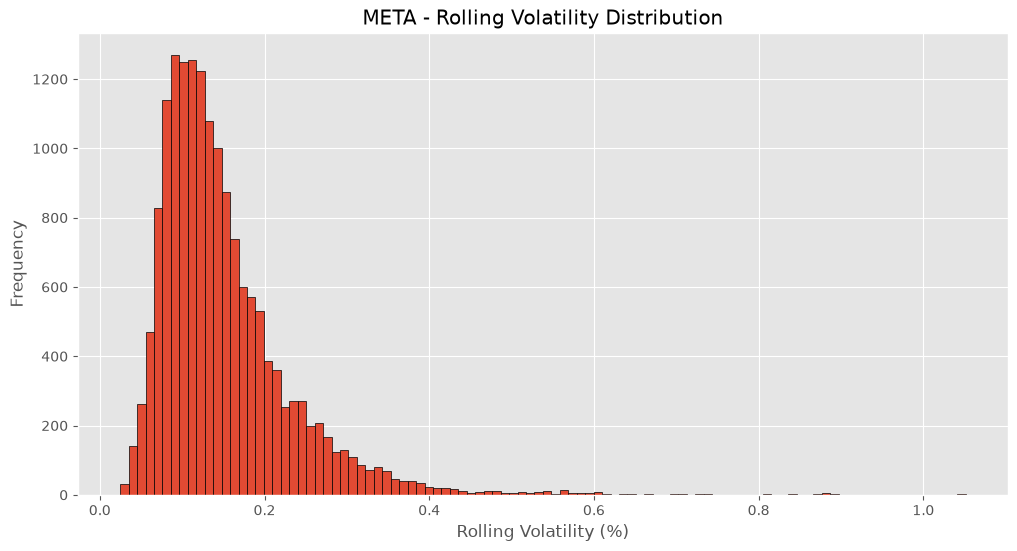

In [12]:
plt.figure(figsize=(12, 6))

plt.hist(
    volatility,
    bins=100,
    edgecolor="black"
)

plt.title("META - Rolling Volatility Distribution")
plt.xlabel("Rolling Volatility (%)")
plt.ylabel("Frequency")

plt.show()

In [13]:
# Identify the 10 highest volatility observations

top_volatility = df.nlargest(
    10,
    "rolling_volatility"
)[
    [
        "ny_timestamp",
        "close",
        "returns",
        "rolling_volatility",
        "volume"
    ]
]

top_volatility

,ny_timestamp,close,returns,rolling_volatility,volume
15774,2026-08-26 10:30:00-04:00,572.955000,-0.198121,1.051419,335490.000000
11459,2026-06-05 14:55:00-04:00,594.810000,0.203841,0.888094,306331.000000
11461,2026-06-05 15:05:00-04:00,591.650000,-0.493705,0.885467,569455.000000
11460,2026-06-05 15:00:00-04:00,594.585500,-0.037743,0.884280,737010.000000
11458,2026-06-05 14:50:00-04:00,593.600000,0.106245,0.882380,374271.000000
11457,2026-06-05 14:45:00-04:00,592.970000,0.161313,0.880621,322570.000000
11455,2026-06-05 14:35:00-04:00,593.450000,0.668352,0.876985,694608.000000
11456,2026-06-05 14:40:00-04:00,592.015000,-0.241806,0.876692,635660.000000
11454,2026-06-05 14:30:00-04:00,589.510000,0.494366,0.839313,635806.000000
11451,2026-06-05 14:15:00-04:00,585.987500,-1.372649,0.811461,1794709.000000


## Observations: Rolling Volatility

1. Mean rolling volatility is approximately 0.15%,
   while median volatility is approximately 0.13%.

2. The mean being higher than the median suggests
   a right-skewed volatility distribution.

3. Volatility varies considerably over time rather
   than remaining constant.

4. The distribution contains a long right tail,
   indicating occasional periods of unusually
   high volatility.

5. Maximum rolling volatility is approximately
   1.05%, substantially higher than the average.

Conclusion:

META exhibits time-varying intraday volatility.
This suggests that volatility-related features
may be useful for distinguishing different
market conditions.

## Volume Analysis

In [14]:
print("Volume Statistics")
print("-----------------")

print("Mean:", df["volume"].mean())
print("Median:", df["volume"].median())
print("Standard Deviation:", df["volume"].std())
print("Minimum:", df["volume"].min())
print("Maximum:", df["volume"].max())
print("Skewness:", df["volume"].skew())

Volume Statistics
-----------------
Mean: 182898.88362157712
Median: 122165.0
Standard Deviation: 204735.89671107888
Minimum: 21667.0
Maximum: 6327773.0
Skewness: 6.205921463658971


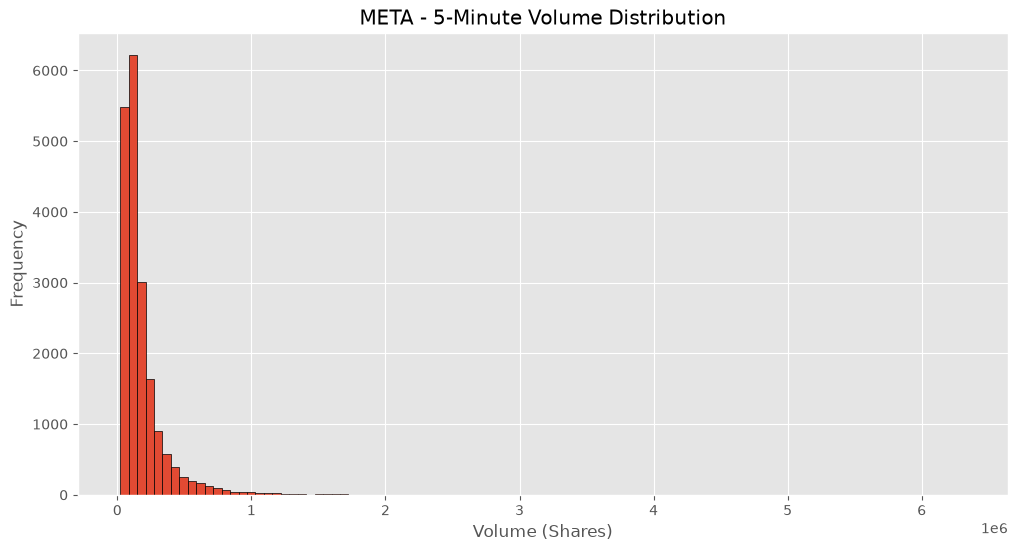

In [15]:
plt.figure(figsize=(12, 6))

plt.hist(
    df["volume"],
    bins=100,
    edgecolor="black"
)

plt.title("META - 5-Minute Volume Distribution")
plt.xlabel("Volume (Shares)")
plt.ylabel("Frequency")

plt.show()

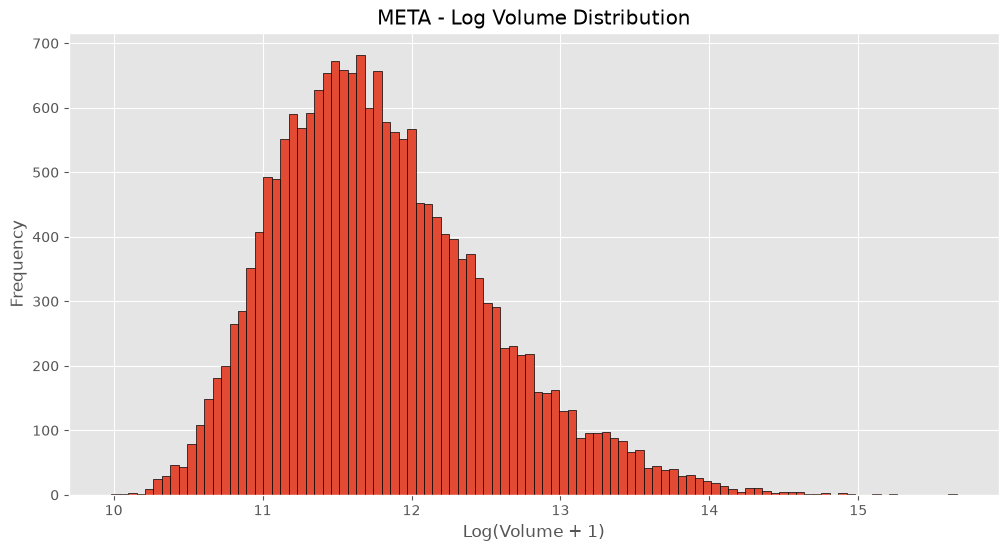

In [16]:
df["log_volume"] = np.log1p(df["volume"])

plt.figure(figsize=(12, 6))

plt.hist(
    df["log_volume"],
    bins=100,
    edgecolor="black"
)

plt.title("META - Log Volume Distribution")
plt.xlabel("Log(Volume + 1)")
plt.ylabel("Frequency")

plt.show()

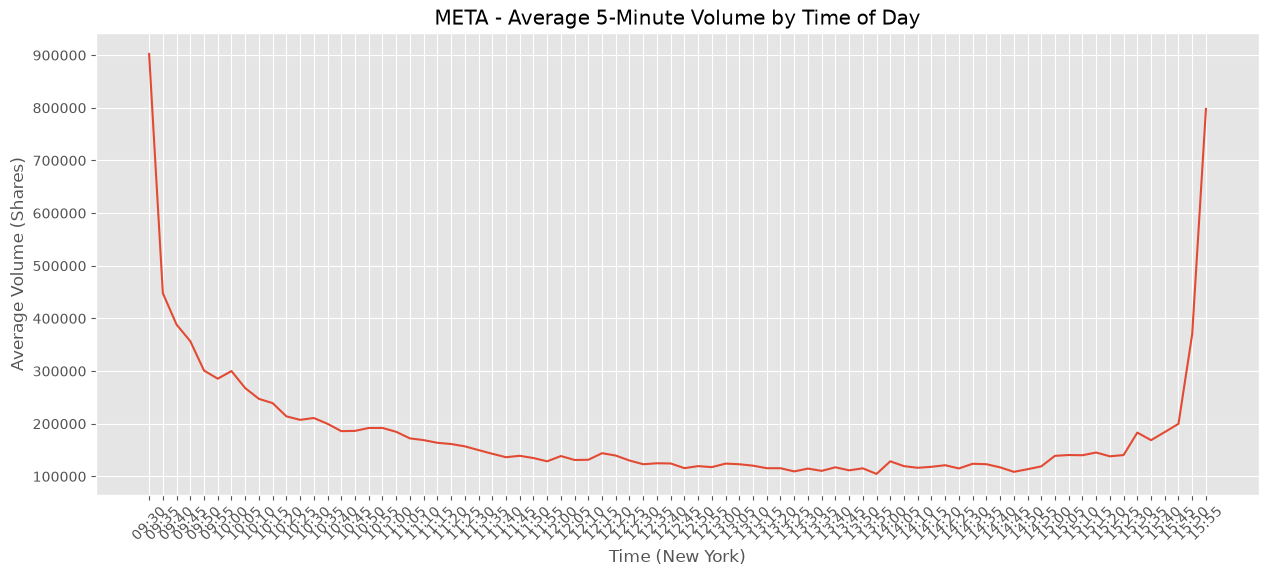

In [17]:
df["time"] = df["ny_timestamp"].dt.strftime("%H:%M")

average_volume = (
    df.groupby("time")["volume"]
      .mean()
)

plt.figure(figsize=(15, 6))

plt.plot(
    average_volume.index,
    average_volume.values
)

plt.title("META - Average 5-Minute Volume by Time of Day")
plt.xlabel("Time (New York)")
plt.ylabel("Average Volume (Shares)")

plt.xticks(rotation=45)

plt.show()

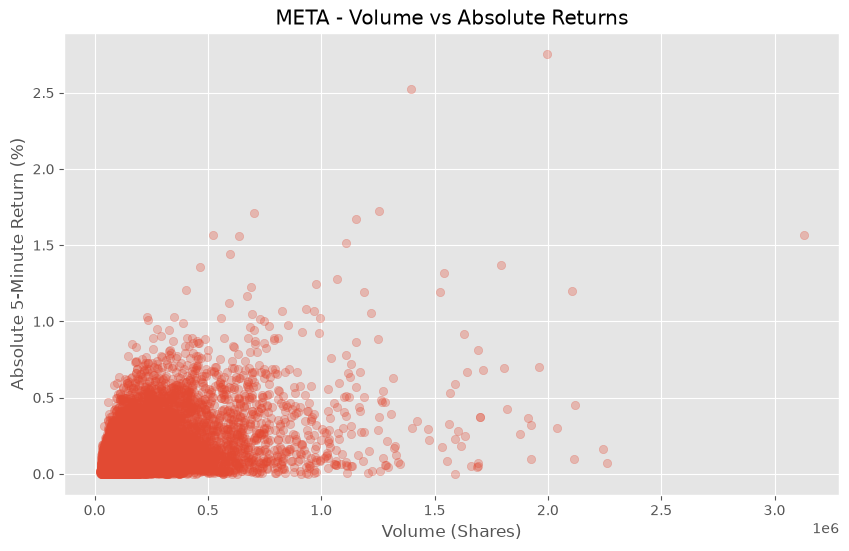

In [18]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["volume"],
    df["returns"].abs(),
    alpha=0.3
)

plt.title("META - Volume vs Absolute Returns")
plt.xlabel("Volume (Shares)")
plt.ylabel("Absolute 5-Minute Return (%)")

plt.show()

## Observations: Volume Analysis

1. Volume distribution is highly right-skewed,
   with a skewness of approximately 6.21.

2. Mean volume is substantially higher than median
   volume, indicating the influence of extreme
   high-volume observations.

3. Log transformation makes the volume distribution
   easier to visualize.

4. Intraday volume exhibits a pronounced U-shaped
   pattern, with high activity near market opening
   and closing and lower activity around midday.

5. Raw volume may not adequately represent unusual
   trading activity because normal volume differs
   throughout the trading session.

Potential feature:
Relative volume, normalized against historical
volume for the same time of day.

6. The relationship between volume and absolute
   returns requires quantitative investigation
   using correlation and volume-group analysis.

#### Correlation Analysis

In [19]:
volume_returns = df[
    ["volume", "returns"]
].dropna().copy()

volume_returns["abs_returns"] = (
    volume_returns["returns"].abs()
)

volume_returns["log_volume"] = np.log1p(
    volume_returns["volume"]
)

print("Pearson Correlation")
print(
    volume_returns[
        ["volume", "abs_returns"]
    ].corr(method="pearson")
)

print("\nSpearman Correlation")
print(
    volume_returns[
        ["volume", "abs_returns"]
    ].corr(method="spearman")
)

print("\nLog Volume vs Absolute Returns")
print(
    volume_returns[
        ["log_volume", "abs_returns"]
    ].corr(method="pearson")
)

Pearson Correlation
              volume  abs_returns
volume      1.000000     0.440156
abs_returns 0.440156     1.000000

Spearman Correlation
              volume  abs_returns
volume      1.000000     0.400108
abs_returns 0.400108     1.000000

Log Volume vs Absolute Returns
             log_volume  abs_returns
log_volume     1.000000     0.452238
abs_returns    0.452238     1.000000


In [20]:
top_volume = df.nlargest(
    10,
    "volume"
)[
    [
        "ny_timestamp",
        "open",
        "high",
        "low",
        "close",
        "volume",
        "returns"
    ]
]

top_volume

,ny_timestamp,open,high,low,close,volume,returns
4530,2026-01-29 09:30:00-05:00,737.450000,744.000000,728.270000,730.790000,6327773.000000,NaN
9444,2026-04-30 09:30:00-04:00,619.320000,620.850000,601.955000,602.005000,4063725.000000,NaN
13188,2026-07-10 09:30:00-04:00,661.260000,677.110000,658.010000,671.027900,4055083.000000,NaN
1680,2025-12-04 09:30:00-05:00,676.000000,676.100000,661.570000,661.960000,3588173.000000,NaN
4531,2026-01-29 09:35:00-05:00,730.750000,731.340000,719.000000,719.345000,3130343.000000,-1.566113
17088,2026-09-21 09:30:00-04:00,680.010000,700.000000,679.600000,699.437500,3007586.000000,NaN
18882,2026-10-22 09:30:00-04:00,676.350000,681.070000,657.400000,657.410000,2909199.000000,NaN
14280,2026-07-30 09:30:00-04:00,525.590000,535.470000,524.480000,531.957700,2890864.000000,NaN
16464,2026-09-09 09:30:00-04:00,648.290000,651.930000,638.560000,643.755000,2694717.000000,NaN
12720,2026-07-01 09:30:00-04:00,607.910000,607.910000,595.100000,601.155000,2691021.000000,NaN


In [21]:
volume_returns["volume_group"] = pd.qcut(
    volume_returns["volume"],
    q=5,
    labels=[
        "Very Low",
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)

volume_analysis = (
    volume_returns
    .groupby("volume_group", observed=True)
    .agg(
        average_volume=("volume", "mean"),
        average_absolute_return=("abs_returns", "mean"),
        median_absolute_return=("abs_returns", "median"),
        observation_count=("volume", "count")
    )
)

volume_analysis

,average_volume,average_absolute_return,median_absolute_return,observation_count
volume_group,,,,
Very Low,56429.967414,0.066416,0.053544,3836
Low,86915.429726,0.087489,0.070232,3835
Medium,121852.642075,0.113919,0.092478,3836
High,181270.329335,0.147842,0.120502,3835
Very High,421110.656934,0.231577,0.173089,3836


## Observations: Volume and Returns Relationship

1. Pearson correlation between volume and absolute
   returns is approximately 0.44.

2. Spearman correlation is approximately 0.40,
   indicating a moderate positive association.

3. Log volume has a slightly higher Pearson
   correlation (approximately 0.45) with absolute
   returns than raw volume.

4. Average absolute returns increase consistently
   across the five volume quintiles.

5. The very-high-volume group has approximately
   3.49 times the average absolute return of the
   very-low-volume group.

Conclusion:

Trading volume is positively associated with the
magnitude of contemporaneous price movements.

Potential features:
- Log volume
- Relative volume
- Volume change
- Rolling average volume

Future predictive usefulness must be evaluated
separately using chronological validation.

## Time of day analysis

In [22]:
df["minute_of_day"] = (
    df["ny_timestamp"].dt.hour * 60
    + df["ny_timestamp"].dt.minute
)

df["minutes_since_open"] = (
    df["minute_of_day"] - (9 * 60 + 30)
)

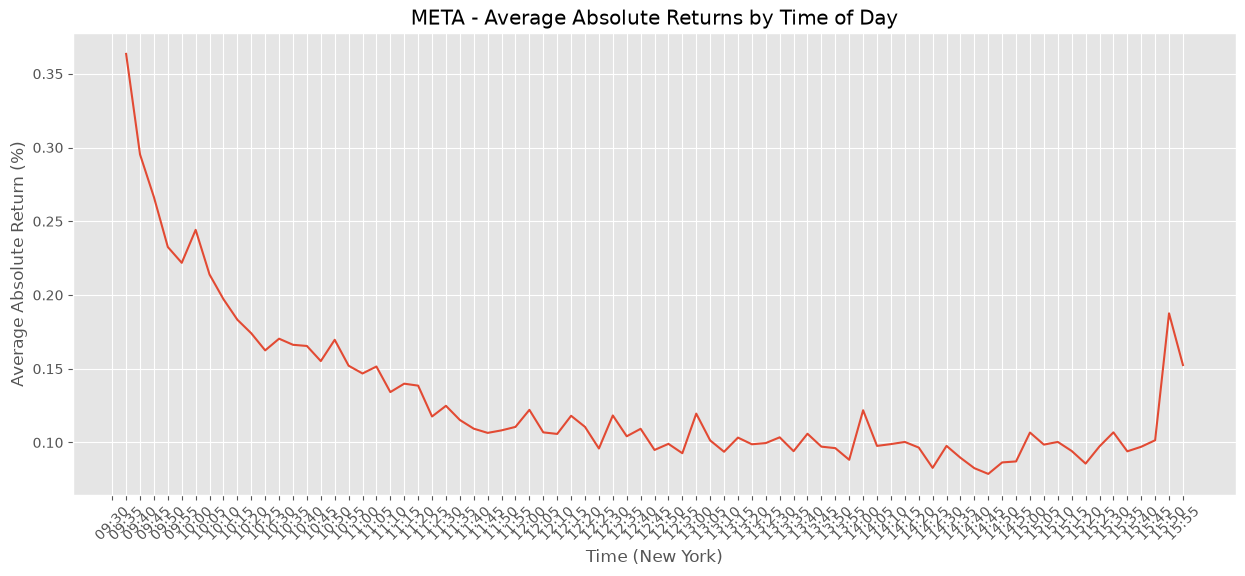

In [23]:
avg_returns_by_time = (
    df.groupby("time")["returns"]
      .apply(lambda x: x.abs().mean())
)

plt.figure(figsize=(15, 6))

plt.plot(
    avg_returns_by_time.index,
    avg_returns_by_time.values
)

plt.title("META - Average Absolute Returns by Time of Day")
plt.xlabel("Time (New York)")
plt.ylabel("Average Absolute Return (%)")

plt.xticks(rotation=45)

plt.show()

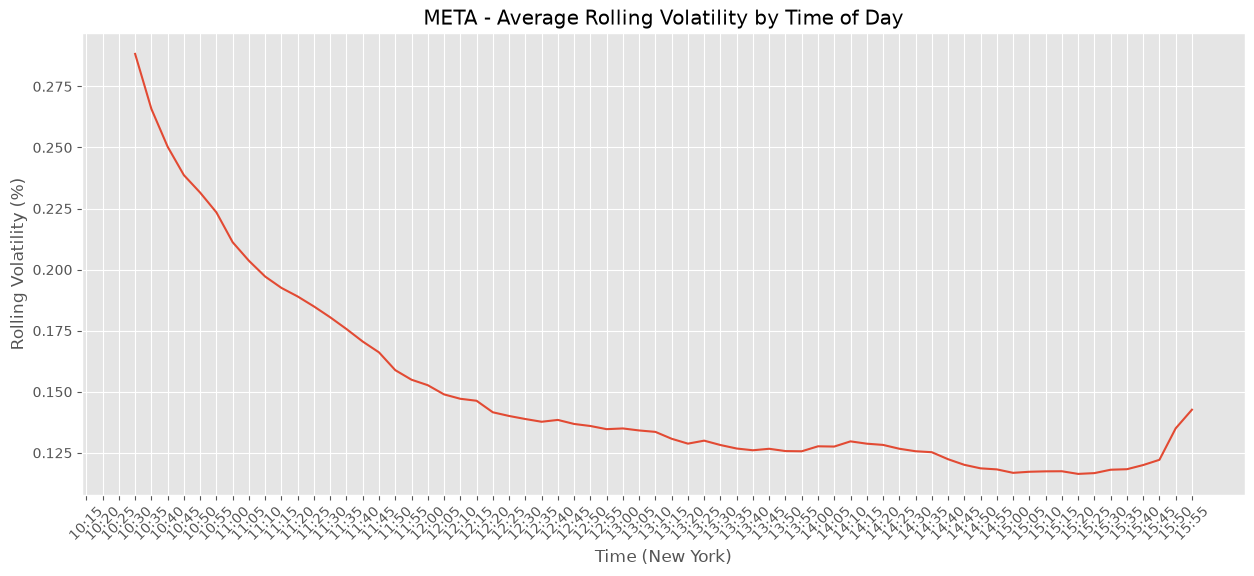

In [24]:
avg_volatility_by_time = (
    df.groupby("time")["rolling_volatility"]
      .mean()
)

plt.figure(figsize=(15, 6))

plt.plot(
    avg_volatility_by_time.index,
    avg_volatility_by_time.values
)

plt.title("META - Average Rolling Volatility by Time of Day")
plt.xlabel("Time (New York)")
plt.ylabel("Rolling Volatility (%)")

plt.xticks(rotation=45)

plt.show()

In [26]:
# Calculate daily statistics for each session period

daily_session_stats = (
    df.groupby(["trading_date", "session_period"])
      .agg(
          average_volume=("volume", "mean"),

          average_absolute_return=(
              "returns",
              lambda x: x.abs().mean()
          ),

          return_volatility=("returns", "std"),

          candle_count=("close", "count")
      )
)

# Average the daily statistics across trading days

session_analysis = (
    daily_session_stats
    .groupby("session_period")
    .mean()
)

session_analysis

,average_volume,average_absolute_return,return_volatility,candle_count
session_period,,,,
Closing,191857.103719,0.102495,0.134324,18.000000
Midday,138606.166133,0.115738,0.152770,47.856000
Opening,346414.642667,0.232222,0.294312,12.000000


## Observations: Time-of-Day Analysis

1. Average absolute returns are highest near market
   opening and generally decrease throughout the day.

2. Rolling volatility also exhibits a declining
   intraday pattern, with an increase near market close.

3. Trading volume is highest during the opening
   period, decreases during midday and increases
   again near closing.

4. Opening-period average volume is approximately
   2.5 times midday average volume.

5. Opening-period average absolute returns are
   approximately twice midday average absolute returns.

Conclusion:

META exhibits significant intraday variation in
trading activity, price movement magnitude and
volatility.

Potential features:
- Minutes since market open
- Relative volume
- Rolling volatility
- Time-of-day indicators

## Final Conclusions — Market Behaviour Analysis

### 1. Returns
- META's 5-minute returns are concentrated around zero.
- The return distribution exhibits heavy tails, with excess kurtosis of approximately 9.98.
- Short-term price movements contain occasional extreme observations.

### 2. Volatility
- Rolling volatility has a mean of approximately 0.15%.
- Volatility varies considerably over time.
- The distribution is right-skewed, indicating occasional high-volatility periods.
- Volatility-related features may help identify different market conditions.

### 3. Volume
- Trading volume is highly right-skewed.
- Mean volume is approximately 183K shares, while median volume is approximately 122K.
- Volume exhibits a U-shaped intraday pattern.
- Pearson correlation between volume and absolute returns is approximately 0.44.
- Average absolute returns increase across volume quintiles.

### 4. Time-of-Day Behaviour
- Opening hours exhibit the highest average volume and return volatility.
- Midday generally exhibits lower trading activity and volatility.
- Trading volume increases again near market closing.
- Intraday market behaviour is not uniform.

### 5. Potential Features for Machine Learning

Based on our exploratory analysis, the following features deserve further investigation:

- Lagged returns
- Rolling volatility
- Log volume
- Relative volume
- Volume percentage change
- Minutes since market open
- Price deviation from VWAP
- Momentum indicators such as RSI and MACD

### Overall Conclusion

META exhibits substantial intraday variation in returns, volatility and trading volume.

These observations provide a foundation for feature engineering. However, exploratory relationships do not establish predictive power. All candidate features must be evaluated using chronological validation without future-data leakage.